In [12]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from google.colab import drive
import seaborn as sns

from sklearn.preprocessing import StandardScaler

import statsmodels.api as sm
from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

drive.mount('/content/gdrive')


Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


In [13]:
# data cleaning/preperation
df=pd.read_csv('gdrive/My Drive/Colab Notebooks/bern 02 stuff/Challenge project/data.csv')

# drop unneeded columns
df = df.drop(columns=['Unnamed: 32','id'])

# Convert diagnosis column to binary
# 1 for malignant and 0 for benign
df['diagnosis'] = df['diagnosis'].apply(lambda x: 1 if x == 'M' else 0)

In [14]:
X = df.drop(columns=['diagnosis'])
y = df['diagnosis']

In [15]:
categorical_cols = X.select_dtypes(include=['object']).columns
numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), categorical_cols)
    ]
)

X_prep = preprocessor.fit_transform(X)
feature_names = preprocessor.get_feature_names_out()
df_X = pd.DataFrame(X_prep, columns=feature_names)


In [16]:
# Setup 10-Fold CV
cv = KFold(n_splits=10, shuffle=True, random_state=42)

# Full Model Variance for Mallows' Cp calculation
full_mod = sm.OLS(y, sm.add_constant(df_X)).fit()
sigma2_full = full_mod.mse_resid
n, p_total = df_X.shape

In [17]:
# Forward Selection Function
def run_forward_selection(df_X, y, cv, sigma2_full):
    n, p = df_X.shape
    remaining = list(df_X.columns)
    selected = []
    records = []

    for k in range(1, p + 1):
        best_rss = np.inf
        best_feat = None

        for feat in remaining:
            X_curr = sm.add_constant(df_X[selected + [feat]])
            model = sm.OLS(y, X_curr).fit()
            if model.ssr < best_rss:
                best_rss = model.ssr
                best_feat = feat

        selected.append(best_feat)
        remaining.remove(best_feat)

        # Fit step k model
        X_best = sm.add_constant(df_X[selected])
        ols_fit = sm.OLS(y, X_best).fit()

        # 10-Fold CV MSE
        scores = cross_val_score(LinearRegression(), df_X[selected], y,
                                 scoring='neg_mean_squared_error', cv=cv)
        cv_mse = -scores.mean()

        records.append({
            'k': k,
            'added_removed': f"+ {best_feat.split('__')[-1]}",
            'RSS': ols_fit.ssr,
            'R2_adj': ols_fit.rsquared_adj,
            'AIC': ols_fit.aic,
            'BIC': ols_fit.bic,
            'Cp': (ols_fit.ssr / sigma2_full) - n + 2 * (k + 1),
            'CV_MSE': cv_mse
        })

    return pd.DataFrame(records)

In [18]:
#  Backward Selection Function
def run_backward_selection(df_X, y, cv, sigma2_full):
    n, p = df_X.shape
    current = list(df_X.columns)
    records = []

    # Record Full Model (k = p)
    X_full = sm.add_constant(df_X[current])
    ols_fit = sm.OLS(y, X_full).fit()
    scores = cross_val_score(LinearRegression(), df_X[current], y,
                             scoring='neg_mean_squared_error', cv=cv)
    records.append({
        'k': p,
        'added_removed': 'Full Model',
        'RSS': ols_fit.ssr,
        'R2_adj': ols_fit.rsquared_adj,
        'AIC': ols_fit.aic,
        'BIC': ols_fit.bic,
        'Cp': (ols_fit.ssr / sigma2_full) - n + 2 * (p + 1),
        'CV_MSE': -scores.mean()
    })

    # Sequential Removal
    for k in range(p - 1, 0, -1):
        best_rss = np.inf
        worst_feat = None

        for feat in current:
            sub_feats = [f for f in current if f != feat]
            X_curr = sm.add_constant(df_X[sub_feats])
            model = sm.OLS(y, X_curr).fit()
            if model.ssr < best_rss:
                best_rss = model.ssr
                worst_feat = feat

        current.remove(worst_feat)

        X_best = sm.add_constant(df_X[current])
        ols_fit = sm.OLS(y, X_best).fit()
        scores = cross_val_score(LinearRegression(), df_X[current], y,
                                 scoring='neg_mean_squared_error', cv=cv)

        records.append({
            'k': k,
            'added_removed': f"- {worst_feat.split('__')[-1]}",
            'RSS': ols_fit.ssr,
            'R2_adj': ols_fit.rsquared_adj,
            'AIC': ols_fit.aic,
            'BIC': ols_fit.bic,
            'Cp': (ols_fit.ssr / sigma2_full) - n + 2 * (k + 1),
            'CV_MSE': -scores.mean()
        })

    return pd.DataFrame(records).sort_values('k').reset_index(drop=True)

In [21]:
# Generate Summary DataFrames
df_fw = run_forward_selection(df_X, y, cv, sigma2_full)
df_bw = run_backward_selection(df_X, y, cv, sigma2_full)

# Print Summaries
print("\nFORWARD SELECTION SUMMARY:")
print(df_fw[['k', 'added_removed', 'RSS', 'R2_adj', 'AIC', 'BIC', 'Cp', 'CV_MSE']])

print("\nBACKWARD SELECTION SUMMARY:")
print(df_bw[['k', 'added_removed', 'RSS', 'R2_adj', 'AIC', 'BIC', 'Cp', 'CV_MSE']])

print("\nForward CV MSE min k:", df_fw.loc[df_fw['CV_MSE'].idxmin(), 'k'], "min MSE:", df_fw['CV_MSE'].min())
print("Backward CV MSE min k:", df_bw.loc[df_bw['CV_MSE'].idxmin(), 'k'], "min MSE:", df_bw['CV_MSE'].min())

print("\nForward AIC min k:", df_fw.loc[df_fw['AIC'].idxmin(), 'k'], "min AIC:", df_fw['AIC'].min())
print("Backward AIC min k:", df_bw.loc[df_bw['AIC'].idxmin(), 'k'], "min AIC:", df_bw['AIC'].min())

print("\nForward BIC min k:", df_fw.loc[df_fw['BIC'].idxmin(), 'k'], "min BIC:", df_fw['BIC'].min())
print("Backward BIC min k:", df_bw.loc[df_bw['BIC'].idxmin(), 'k'], "min BIC:", df_bw['BIC'].min())


FORWARD SELECTION SUMMARY:
     k              added_removed        RSS    R2_adj         AIC  \
0    1     + concave points_worst  49.248201  0.629094  226.404727   
1    2             + radius_worst  41.204812  0.689123  126.941899   
2    3            + texture_worst  38.119417  0.711893   84.655910   
3    4               + area_worst  36.885276  0.720726   67.929370   
4    5            + smoothness_se  35.199917  0.733013   43.317966   
5    6           + symmetry_worst  34.140248  0.740590   27.925484   
6    7           + compactness_se  33.695774  0.743511   22.468992   
7    8                + radius_se  33.015037  0.748244   12.856101   
8    9  + fractal_dimension_worst  32.453066  0.752086    5.087394   
9   10         + compactness_mean  31.988097  0.755200   -1.123881   
10  11      + concave points_mean  31.375684  0.759456  -10.123034   
11  12          + concavity_worst  31.138241  0.760847  -12.445449   
12  13             + concavity_se  30.775558  0.763207  -17.11

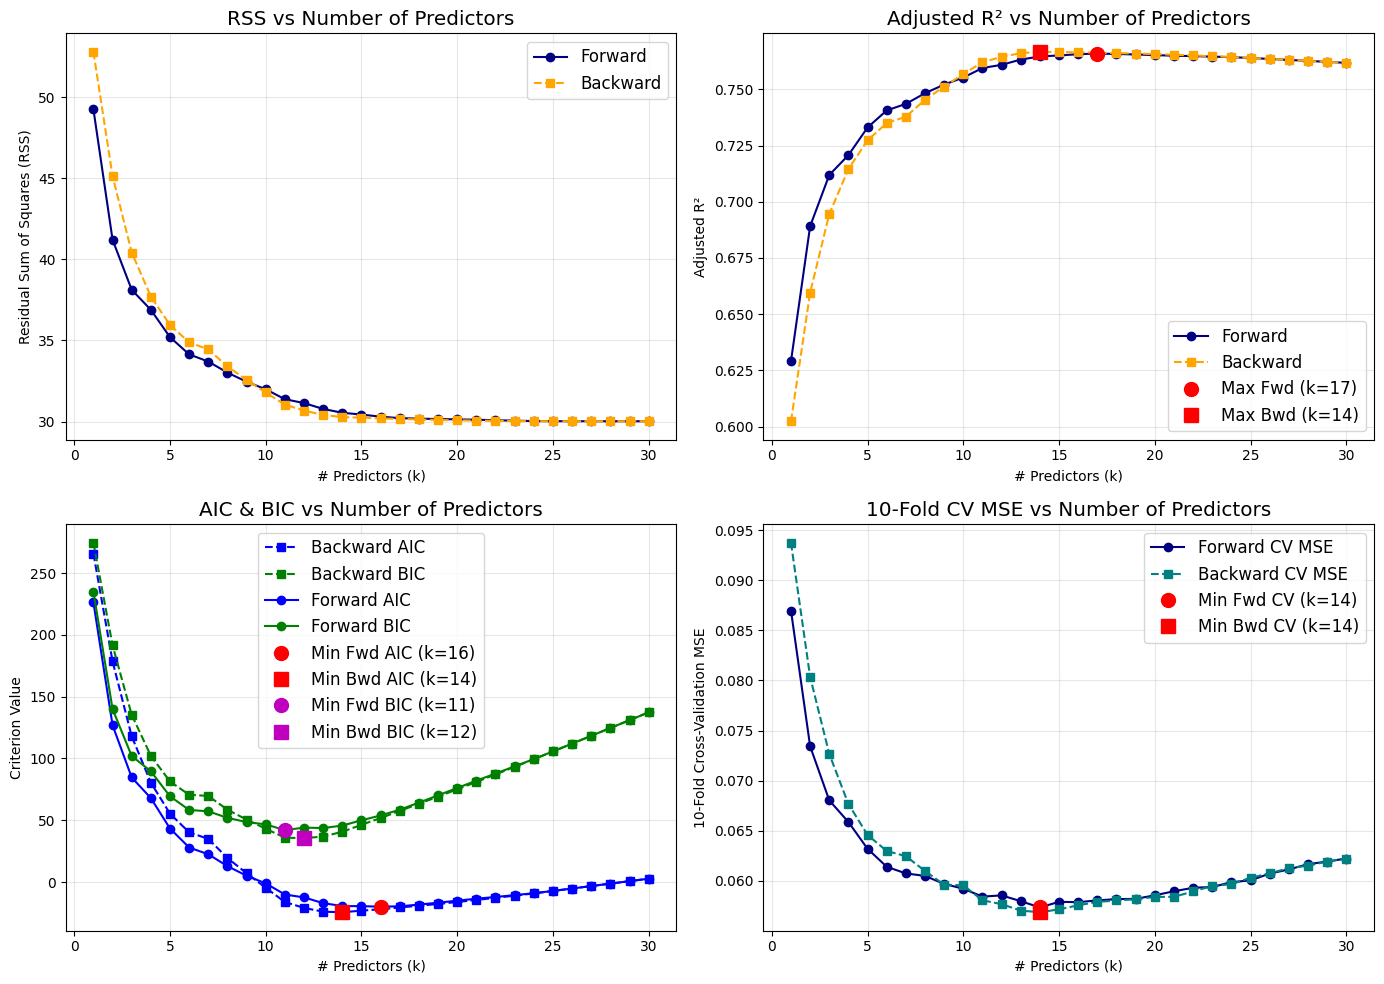

In [20]:
# Plotting Comparison Grid
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
plt.rcParams.update({'font.size': 12})

# 1. RSS
axes[0, 0].plot(df_fw['k'], df_fw['RSS'], marker='o', linestyle='-', label='Forward', color='navy')
axes[0, 0].plot(df_bw['k'], df_bw['RSS'], marker='s', linestyle='--', label='Backward', color='orange')
axes[0, 0].set_xlabel('# Predictors (k)')
axes[0, 0].set_ylabel('Residual Sum of Squares (RSS)')
axes[0, 0].set_title('RSS vs Number of Predictors')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# 2. Adjusted R2
axes[0, 1].plot(df_fw['k'], df_fw['R2_adj'], marker='o', linestyle='-', label='Forward', color='navy')
axes[0, 1].plot(df_bw['k'], df_bw['R2_adj'], marker='s', linestyle='--', label='Backward', color='orange')
best_bw_r2 = df_bw.loc[df_bw['R2_adj'].idxmax()]
best_fw_r2 = df_fw.loc[df_fw['R2_adj'].idxmax()]
axes[0, 1].plot(best_fw_r2['k'], best_fw_r2['R2_adj'], 'ro', markersize=10, label=f'Max Fwd (k={best_fw_r2["k"]})')
axes[0, 1].plot(best_bw_r2['k'], best_bw_r2['R2_adj'], 'rs', markersize=10, label=f'Max Bwd (k={best_bw_r2["k"]})')
axes[0, 1].set_xlabel('# Predictors (k)')
axes[0, 1].set_ylabel('Adjusted R²')
axes[0, 1].set_title('Adjusted R² vs Number of Predictors')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# 3. AIC & BIC (Backward)
axes[1, 0].plot(df_bw['k'], df_bw['AIC'], 'b--s', label='Backward AIC')
axes[1, 0].plot(df_bw['k'], df_bw['BIC'], 'g--s', label='Backward BIC')
axes[1, 0].plot(df_bw['k'], df_fw['AIC'], 'b-o', label='Forward AIC')
axes[1, 0].plot(df_bw['k'], df_fw['BIC'], 'g-o', label='Forward BIC')
best_bw_r2 = df_bw.loc[df_bw['AIC'].idxmin()]
best_fw_r2 = df_fw.loc[df_fw['AIC'].idxmin()]
axes[1, 0].plot(best_fw_r2['k'], best_fw_r2['AIC'], 'ro', markersize=10, label=f'Min Fwd AIC (k={best_fw_r2["k"]})')
axes[1, 0].plot(best_bw_r2['k'], best_bw_r2['AIC'], 'rs', markersize=10, label=f'Min Bwd AIC (k={best_bw_r2["k"]})')


best_bw_r2 = df_bw.loc[df_bw['BIC'].idxmin()]
best_fw_r2 = df_fw.loc[df_fw['BIC'].idxmin()]
axes[1, 0].plot(best_fw_r2['k'], best_fw_r2['BIC'], 'mo', markersize=10, label=f'Min Fwd BIC (k={best_fw_r2["k"]})')
axes[1, 0].plot(best_bw_r2['k'], best_bw_r2['BIC'], 'ms', markersize=10, label=f'Min Bwd BIC (k={best_bw_r2["k"]})')



axes[1, 0].set_xlabel('# Predictors (k)')
axes[1, 0].set_ylabel('Criterion Value')
axes[1, 0].set_title('AIC & BIC vs Number of Predictors')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# 4. CV MSE Comparison
axes[1, 1].plot(df_fw['k'], df_fw['CV_MSE'], marker='o', linestyle='-', label='Forward CV MSE', color='navy')
axes[1, 1].plot(df_bw['k'], df_bw['CV_MSE'], marker='s', linestyle='--', label='Backward CV MSE', color='teal')
best_fw_cv = df_fw.loc[df_fw['CV_MSE'].idxmin()]
best_bw_cv = df_bw.loc[df_bw['CV_MSE'].idxmin()]
axes[1, 1].plot(best_fw_cv['k'], best_fw_cv['CV_MSE'], 'ro', markersize=10, label=f'Min Fwd CV (k={best_fw_cv["k"]})')
axes[1, 1].plot(best_bw_cv['k'], best_bw_cv['CV_MSE'], 'rs', markersize=10, label=f'Min Bwd CV (k={best_bw_cv["k"]})')
axes[1, 1].set_xlabel('# Predictors (k)')
axes[1, 1].set_ylabel('10-Fold Cross-Validation MSE')
axes[1, 1].set_title('10-Fold CV MSE vs Number of Predictors')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()